# Reading a paper: quantum gravity from the null cone

*Reading research papers, part 1.* [Index](README.md)

A black hole of the mass of the Sun has an entropy of about $10^{77}$ in units of Boltzmann's constant: more than all
the stars in the observable universe put together. Jacob Bekenstein and Stephen Hawking found in the 1970s that this
entropy is a quarter of the horizon area in Planck units, $S = A/4G\hbar$ (with $c = k_B = 1$). Entropy counts states:
$S = \log(\text{number of states})$. So what are the $e^{10^{77}}$ states of a black hole? Answering that needs a
quantum theory of gravity, which we do not yet have.

In November 2026 Venkatesa Chandrasekaran posted a proposal, "An algebraic quantization of gravity from the null cone"
(arXiv:2611.34924). Its idea is to cut spacetime into **causal diamonds**, regions bounded by light cones, because on a
light cone the constraints of Einstein's equations can be integrated along the light rays, which makes it possible to
write down the free data of the theory and quantize it. The paper claims that a diamond of bounded size has finitely
many quantum states, whose count reproduces $A/4G\hbar$ together with a known logarithmic correction.

This lesson follows the paper from beginning to end, each step with a computation you can check: the entropy numbers,
causal diamonds, the two-dimensional toy model and its "clock", the focusing equation that limits areas, the quantum
states and the trace (sections 1 to 7 of the lesson, the paper's sections 2 and 3); then the Gaussian states of
gravitons, the sum over gravitons of every wavelength, the argument that areas come in discrete values, the entropy
with its logarithmic correction, two-sided black holes, and the classical limit (sections 8 to 13, the paper's sections
4 to 6). It does not prove the paper's results. It prepares you to read the paper, and shows which of its steps are
calculations you can redo.

**Three levels of reading.** Each step of the paper can be met at three levels, and the lesson says at each step which
one it reaches:

* **Reproduce:** run the calculation and get the paper's number or formula.
* **Understand:** say in plain words why the calculation matters, physically and mathematically.
* **Validate:** decide whether the calculation, with all its assumptions, establishes the paper's claim.

The computations here reach the first two levels. The third is for the reader, the experts and follow-up papers; the
lesson points out where it is still open, and the [map at the end](#A-map-of-the-paper) collects them.

**Who this is for.** Students who have done the [general relativity](../general-relativity/README.md) path through
[black holes](../general-relativity/04-black-holes.ipynb), and who have seen the basics of quantum mechanics (states,
inner products, $[x, p] = i\hbar$).

**What you will be able to do afterwards:**

1. compute the Bekenstein–Hawking entropy and temperature of a black hole;
2. explain what a causal diamond is and why null cones simplify Einstein's equations;
3. derive the clock formula of the paper's two-dimensional model and solve its constraint equation;
4. use the focusing equation to bound the area of a diamond;
5. check that the paper's quantum states are orthonormal, and see where $e^{-A/4G\hbar}$ enters;
6. compute with Gaussian states and Fock spaces, and sum a series of graviton pairs into a dilogarithm;
7. follow the paper's argument that the area of a bounded diamond takes finitely many values;
8. derive the entropy $S = \langle A\rangle/4G\hbar + \log Z$ and reproduce the arithmetic of its logarithmic
   correction.

Plan four to six hours, depending on how many exercises you do, in two sittings: sections 1 to 7, then 8 to 13. Sections
9 to 11 are the most demanding (marked *advanced*). For the story without all the calculations, read their opening
paragraphs, the numbered chain of reasoning in section 10 and the four distinctions at the start of section 11, and skip
their code cells. This is a preprint (version 1, posted 25 November 2026, not yet peer reviewed): read it as a proposal
to be tested.

## 1. The entropy of a black hole

A non-rotating black hole of mass $M$ has horizon radius $r_s = 2GM/c^2$ and area $A = 4\pi r_s^2$. The
Bekenstein–Hawking entropy is $A$ divided by four times the Planck area $\ell_P^2 = \hbar G/c^3$, and Hawking's
temperature is $T = \hbar c^3/(8\pi G M k_B)$. For the Sun's mass:

In [1]:
G0 = 6.674e-11; c0 = 2.998e8; hbar0 = 1.0546e-34; kB = 1.380649e-23; Msun = 1.989e30;
rs = 2*G0*Msun/c0^2
area0 = eval(4*pi*rs^2)
lp2 = hbar0*G0/c0^3
S0 = area0/(4*lp2)
T0 = eval(hbar0*c0^3/(8*pi*G0*Msun*kB))

2953.845147376436
109644111.39453493

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.612035552127084e-70
1.0494125099603581e77
6.169337433251986e-8

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The horizon is 2.95 km in radius, the entropy is $1.05 \times 10^{77}$, and the temperature is 62 billionths of a
kelvin. The entropy is proportional to the **area**, not the volume. For ordinary matter, entropy grows with volume.
That a region's maximum entropy grows with its boundary area is the clue every approach to quantum gravity tries to
explain, and the reason the paper works with surfaces and light cones.

**Try this.** How does $S$ scale with $M$? Double the mass and compare. Is a black hole's heat capacity positive or
negative? (Hint: how does $T$ change when $M$ grows?)

## 2. Causal diamonds and null cones

Take two events $p$ (earlier) and $q$ (later). Everything that can be influenced by $p$ and can influence $q$ forms a
**causal diamond**: the region inside the future light cone of $p$ and the past light cone of $q$. In one space
dimension with $c = 1$ it is a square standing on a corner. Its boundary consists of four **null** segments (light rays),
and its left and right corners are where the two cones meet; in four dimensions that meeting place is a sphere, the
**corner** $S$.

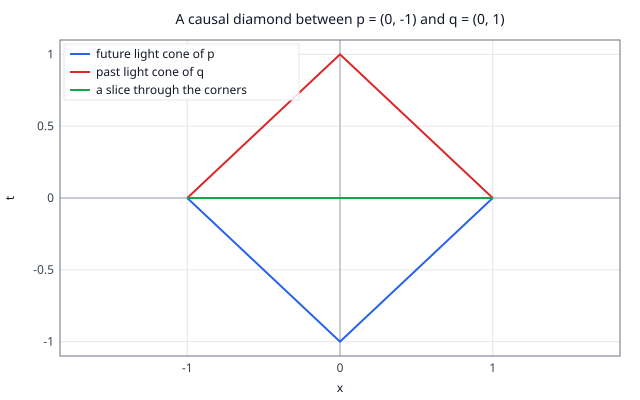

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
p = parametric(x, abs(x) - 1, x, -1, 1);
p = show(p, parametric(x, 1 - abs(x), x, -1, 1));
p = show(p, parametric(x, 0, x, -1, 1));
p = legend(p, "future light cone of p", "past light cone of q", "a slice through the corners");
labels(title(p, "A causal diamond between p = (0, -1) and q = (0, 1)"), "x", "t")

Why light cones? On a spacelike slice, Einstein's equations include **constraints** that couple the geometric data
across the whole slice; they must be solved before one can say what the physical degrees of freedom are, and that is a
large part of what makes quantizing gravity hard. On a null hypersurface the characteristic data are organized along
the light rays, and important constraints, including the focusing equation (the **Raychaudhuri** equation, section 4
below), can be integrated along each ray. The paper uses this structure, together with data at the corners and
boundaries of the diamond (edge modes) and the way neighboring diamonds are matched, to construct a **reduced phase
space** of freely specifiable data, which it then quantizes. The point is not that every constraint disappears
automatically, or that this solves the constraint problem of gravity in general, but that the null formulation makes
the reduction tractable in this construction. The paper's section 3 and appendix A carry out the full reduction; this
lesson follows only the focusing part.

**Try this.** In the picture, which events can send a light signal to $q$ but cannot receive one from $p$? Are they
inside the diamond?

## 3. The two-dimensional model and its clock

Why does a theory of gravity need a clock? In ordinary mechanics we follow a system against an external time $t$. In
gravity there is no external time: time is part of the geometry that is being quantized. The paper therefore builds a
**relational clock** out of the geometry of the causal diamond itself, a number $u_*$ read off at its corner, and makes
that reading a variable of the phase space, with a conjugate momentum. Keep this in mind through the formulas below:
they compute what the clock reads.

The paper first works out a simpler theory, **Jackiw–Teitelboim gravity**: two spacetime dimensions, a curved spacetime
called anti-de Sitter space $\text{AdS}_2$, a scalar field $\Phi$ called the dilaton (it plays the role of the area of
the corner sphere), and a matter field $\phi$. In global coordinates the metric is

$$ds^2 = \frac{L^2}{\cos^2\sigma}\left(-d\tau^2 + d\sigma^2\right), \qquad -\pi/2 < \sigma < \pi/2.$$

In [3]:
ads = metric([tau sigma], [-L^2/cos(sigma)^2 0; 0 L^2/cos(sigma)^2]);
christoffel(ads)
ricciscalar(ads)

**Christoffel symbols of the second kind** (coordinates $\tau$, $\sigma$)

$$\begin{aligned}
\Gamma{}^{\tau}{}_{\tau}{}_{\sigma} &= \frac{\sin\left(\sigma\right)}{\cos\left(\sigma\right)} \\
\Gamma{}^{\sigma}{}_{\tau}{}_{\tau} &= \frac{\sin\left(\sigma\right)}{\cos\left(\sigma\right)} \\
\Gamma{}^{\sigma}{}_{\sigma}{}_{\sigma} &= \frac{\sin\left(\sigma\right)}{\cos\left(\sigma\right)}
\end{aligned}$$

> `christoffel`: Christoffel symbols of the second kind Gamma^a_bc (christoffelsecond is the same), or of the first kind Gamma_abc.

-2/L^2

> `ricciscalar` (see `riccitensor`): Ricci tensor R_ab and Ricci scalar R.

The curvature is constant and negative, $R = -2/L^2$. Proper distance along the slice $\tau = 0$ is
$\lambda = L\int_0^\sigma \sec s\,ds$. The paper uses the coordinate $u = L\tan\sigma$ and states that
$u = L\sinh(\lambda/L)$. Check it by differentiating: if $\lambda = L\,\operatorname{asinh}(\tan\sigma)$, then
$d\lambda/d\sigma$ must equal $L/\cos\sigma$:

In [4]:
simplify(diff(L*asinh(tan(s)), s))

L/(cos(s)^2*sqrt(tan(s)^2+1))

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

That is $L/(\cos^2 s\,\sec s) = L/\cos s$ for $|s| < \pi/2$, since $\sqrt{\tan^2 s + 1} = \sec s$. The paper's **clock**
is the reading $u_*$ of this coordinate at the corner, measured from a cut at distance $\lambda_c = \epsilon w/2$ from
the middle of a slice of length $w$, where $0 < \epsilon < 1$ (equation 2.4c):

$$u_*(w) = L\,\frac{\sinh\!\big(w/2L\big) - \sinh\!\big(\lambda_c/L\big)}{\cosh\!\big(\lambda_c/L\big)}.$$

In [5]:
ustar = L*(sinh(w/(2*L)) - sinh(lc/L))/cosh(lc/L);
taylor(subs(subs(ustar, lc, ep*w/2), L, 1), w, 0, 3)

w^3*(2*ep^3-3*ep^2+1)/48+w*(1-ep)/2

> `taylor`: Taylor polynomial of f around x = a (default 0) up to the term (x-a)^n.

For small diamonds, $u_* \approx (1 - \epsilon)w/2$: the clock measures the distance from the cut to the corner, as it
should in nearly flat space. For large ones the curvature makes it grow exponentially:

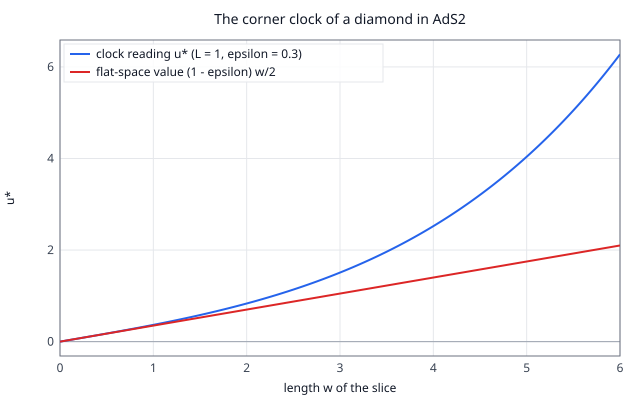

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
u1 = subs(subs(ustar, lc, 0.3*w/2), L, 1);
p = plot(u1, w, 0, 6);
p = show(p, plot(0.7*w/2, w, 0, 6));
p = legend(p, "clock reading u* (L = 1, epsilon = 0.3)", "flat-space value (1 - epsilon) w/2");
labels(title(p, "The corner clock of a diamond in AdS2"), "length w of the slice", "u*")

Back to the question of why this is a clock: the reading $u_*$ grows monotonically with the size of the diamond, it is
defined by the geometry alone, and in the quantum theory it becomes an operator with a conjugate momentum $p_{u_*}$.
Dynamics is then described relationally, as how the other variables change with the clock reading. This is how a
theory without a background time can still have dynamics.

**Try this.** Compute one more term of the series, `taylor(subs(subs(ustar, lc, ep*w/2), L, 1), w, 0, 5)`. At what
length $w$ does the $w^3$ correction reach 10% of the leading term when $\epsilon = 0.3$?

## 4. The null constraint: matter focuses light

Along a light ray of the cone, with affine parameter $u$, the dilaton obeys the paper's equation 2.5:

$$\frac{d^2\Phi}{du^2} = -\left(\frac{d\phi}{du}\right)^2.$$

The right side is never positive: matter crossing the cone makes $\Phi$ bend down. This is the two-dimensional form of
the **Raychaudhuri equation**, which says that energy focuses light rays. Its solution with $\Delta\Phi(0) = 0$ and
$\Delta\Phi'(0) = 0$ is

$$\Delta\Phi(u_*) = -\int_0^{u_*} (u_* - u)\left(\frac{d\phi}{du}\right)^2 du.$$

Check this for a matter pulse $\phi = \sin(\pi u)$, so $(\phi')^2 = \pi^2\cos^2(\pi u)$, by solving the differential
equation directly and evaluating the integral formula:

In [7]:
dsolve(d(y, x, 2) == -pi^2*(1 + cos(2*pi*x))/2, y, x, 0, [0 0])
integrate(-(x - u)*pi^2*cos(pi*u)^2, u, 0, x)

(cos(2*pi*x)-2*pi^2*x^2-1)/8

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

(cos(2*pi*x)-2*pi^2*x^2-1)/8

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

The two agree: $\Delta\Phi = (\cos 2\pi x - 2\pi^2x^2 - 1)/8$. The constraint has been **solved**: the dilaton is no
longer an independent variable but is fixed by the matter on the cone. What stays free is the matter data $\phi$ on the
cones and the clock $u_*$ (with corner data that the paper also keeps). That is the reduced phase space of the
two-dimensional model.

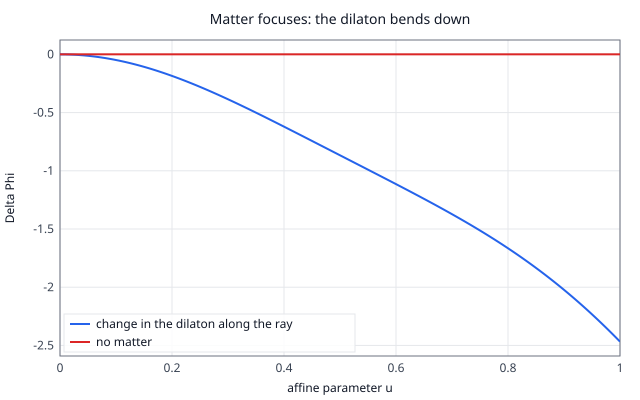

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = plot((cos(2*pi*x) - 2*pi^2*x^2 - 1)/8, x, 0, 1);
p = show(p, plot(0, x, 0, 1));
p = legend(p, "change in the dilaton along the ray", "no matter");
labels(title(p, "Matter focuses: the dilaton bends down"), "affine parameter u", "Delta Phi")

**Try this.** Take a weaker pulse, $\phi = \tfrac12\sin(\pi u)$. How does $\Delta\Phi(1)$ change? (The equation is
quadratic in $\phi$.)

## 5. Four dimensions: shear, focusing and an area bound

In four dimensions the corner is a sphere, labelled by angles $y$ on the unit sphere. Along each light ray $\gamma_y$ the
**area radius** $\varrho$ (so that the corner area is $A = \int_S \varrho_S^2\,d\Omega$) obeys equation 3.25f:

$$\frac{d^2\varrho}{du^2} + \frac{\varrho}{8}\,(\partial_u \bar q)^{AB}(\partial_u \bar q)_{AB} = 0.$$

Here $\bar q$ is the shape of the sphere and $\partial_u\bar q$ its **shear**: gravitational waves crossing the cone.
The shear term is never negative, so gravitational waves focus light just as matter does. For a steady shear with
$(\partial_u\bar q)^2 = 8k^2$ the equation is $\varrho'' = -k^2\varrho$:

cos(k*x)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

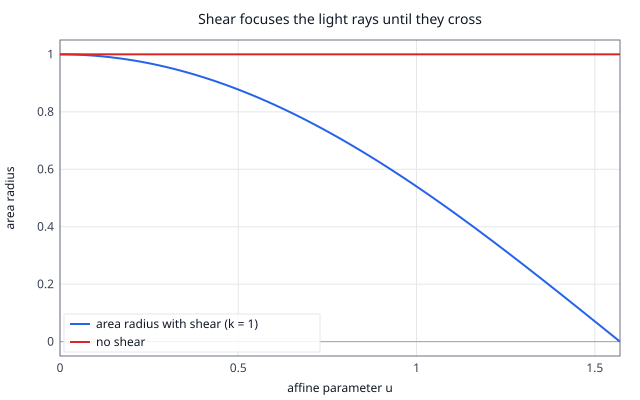

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
dsolve(d(y, x, 2) + k^2*y == 0, y, x, 0, [1 0])
p = plot(cos(x), x, 0, pi/2);
p = show(p, plot(1, x, 0, pi/2));
p = legend(p, "area radius with shear (k = 1)", "no shear");
labels(title(p, "Shear focuses the light rays until they cross"), "affine parameter u", "area radius")

The rays meet after $u = \pi/2k$: a **caustic**, where the cone stops being a smooth boundary. The paper handles
caustics by gluing several diamonds together (its figures 7 to 10).

Focusing gives the paper's clock in four dimensions (equation 3.27):

$$u_*(y) = \varrho_S(y)\int_\epsilon^1 e^{\Xi_y(v)}\,dv, \qquad \Xi_y(v) = \frac18\int_\epsilon^v s\,(\partial_s\bar q)^{AB}(\partial_s\bar q)_{AB}\,ds \ \ge 0.$$

Since $\Xi_y \ge 0$, every exponential is at least 1, so $u_*(y) \ge (1 - \epsilon)\varrho_S(y)$: **shear makes the
clock run further**. Average the clock over the sphere with weight $\varrho_S$,
$\bar u_* = \int_S \varrho_S u_*\,d\Omega \big/ \int_S \varrho_S\,d\Omega$. Then

$$\bar u_* \ \ge\ (1 - \epsilon)\,\frac{\int \varrho_S^2\,d\Omega}{\int \varrho_S\,d\Omega} \ \ge\ (1 - \epsilon)\,\frac{A}{\sqrt{4\pi A}} = (1 - \epsilon)\sqrt{\frac{A}{4\pi}},$$

where the second step is the **Cauchy–Schwarz inequality** $\left(\int \varrho_S\,d\Omega\right)^2 \le
\int 1\,d\Omega \int \varrho_S^2\,d\Omega = 4\pi A$. Check it for a lopsided corner, $\varrho_S = 1 + \cos\theta/2$,
with no shear ($u_* = (1 - \epsilon)\varrho_S$):

In [10]:
rho = 1 + cos(th)/2;
area = integrate(2*pi*rho^2*sin(th), th, 0, pi)
I1 = integrate(2*pi*rho*sin(th), th, 0, pi)
ubar = (1 - ep)*area/I1
ratio = simplify(ubar/((1 - ep)*sqrt(area/(4*pi))))
eval(ratio)

13*pi/3

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

4*pi

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

13*(1-ep)/12

13/(6*sqrt(13/3))

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

1.0408329997330663

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The ratio is $\sqrt{13/12} \approx 1.04 \ge 1$, as the inequality promises; it equals 1 only for a round corner.
**A diamond whose clock is bounded, $\bar u_* \le \ell$, has bounded area**, $A \le 4\pi\ell^2/(1 - \epsilon)^2$. The
paper derives the same bound in its equation 5.21.

This is a **geometric** result: a bounded clock reading implies a bounded corner area. It does not by itself show that
the quantum Hilbert space has finitely many states, because a bounded range of areas can still hold infinitely many
states. The paper treats that separate question in its section 5.2, with a consistency argument about corner boosts and
graviton correlations; section 10 below follows it.

**In your own words.** Explain to a classmate, without formulas, why gravitational waves crossing the cone can only make
the clock run further, and why that limits the area.

**Try this.** Repeat with $\varrho_S = 1 + \cos\theta$. Is the ratio larger or smaller? Why? For any
$\varrho_S = 1 + a\cos\theta$ with $|a| < 1$ the ratio is $R(a) = \sqrt{1 + a^2/3}$ (exercise 4).

## 6. Quantum states of the clock

Quantizing turns the free data into operators. The clock becomes multiplication by $u_*$ on wavefunctions $\psi(u_*)$,
the matter field becomes oscillators $\mathfrak a_j$ with $[\mathfrak a_j, \mathfrak a_k^\dagger] = \delta_{jk}$, and
the Hilbert space of a diamond whose clock reads at most $\ell$ is $L^2([0, \ell], du_*)$ times the matter states
(equation 2.13c). The paper builds the states (2.14)

$$\Psi_n(u_*) = h(u_*)\,e^{2\pi i n F(u_*)}\,|\xi\rangle, \qquad F(u_*) = \int_0^{u_*} |h(v)|^2\,dv,$$

from a normalized clock wavefunction $h$ and a fixed matter state $|\xi\rangle$. Take $\ell = 1$ and
$h(u) = \sqrt2\sin(\pi u)$:

In [11]:
integrate(2*sin(pi*u)^2, u, 0, 1)
F = integrate(2*sin(pi*v)^2, v, 0, u)

1

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

(pi*u-sin(2*pi*u)/2)/pi

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

$F$ rises from 0 to 1, so the substitution $s = F(u)$, $ds = |h|^2\,du$, turns the inner product into a Fourier
integral:

$$\langle \Psi_m | \Psi_n\rangle = \int_0^1 |h|^2 e^{2\pi i (n - m)F}\,du = \int_0^1 e^{2\pi i (n - m)s}\,ds = \delta_{mn}.$$

In [12]:
integrate(exp(2*pi*i*2*s), s, 0, 1)
integrate(exp(2*pi*i*0*s), s, 0, 1)
round(integrate(2*sin(pi*u)^2*cos(2*pi*3*F), u, 0, 1), 12)

0

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

0.0

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

The last line checks one case without the substitution. So there are infinitely many orthonormal states, even though
the clock is confined to $[0, 1]$: they differ in how fast their phase winds. They also carry different "dilation
charge" (equation 2.15): the expectation of $\mathcal Q = -i\hbar(u_*\partial_{u_*} + \tfrac12)$ grows by
$2\pi n\hbar\int u_*|h|^4\,du_*$:

In [13]:
2*pi*integrate(u*(2*sin(pi*u)^2)^2, u, 0, 1)

3*pi/2

That is $3\pi/2$ per unit of $n\hbar$ for this $h$.

**Try this.** Use the clock wavefunction $h = \sqrt 3\,u$ on $[0, 1]$. Check that it is normalized, compute $F$, and
recompute the dilation charge per unit of $n\hbar$.

## 7. The trace, and where the entropy comes from

To compute an entropy one needs a **trace**: a sum of $\langle\Psi|W|\Psi\rangle$ over a basis. The paper glues a
diamond to its time reflection; at each corner the gluing contributes a factor $e^{-\pi K/\hbar}$ from half a turn of
the boost generated by $K$, and the result is (2.17a)

$$\langle\Psi_m|W|\Psi_n\rangle = e^{-2\pi(K_L + K_R)/\hbar}\,\delta_{mn}.$$

In the two-dimensional model each of the infinitely many states $\Psi_n$ of section 6 contributes the same amount, so
$\operatorname{Tr} W \ge N e^{-2\pi(K_L + K_R)/\hbar}$ for every $N$: the trace is infinite.

In four dimensions the boost charge of a corner is $K = A/8\pi G$ (equation 3.43), so the weight of one corner is

In [14]:
simplify(2*pi*(A/(8*pi*G))/hbar)

A/(4*G*hbar)

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

$2\pi K/\hbar = A/4G\hbar$: **the Bekenstein–Hawking entropy appears in the exponent**. A state of corner area $A$
enters the trace with weight $e^{-A/4G\hbar}$ (the paper's equation 5.23b). In four dimensions the trace is finite only
if the diamond has finitely many states; sections 8 to 11 follow the paper's argument that it does, and what the count
gives.

**In your own words.** Why is the trace infinite in the two-dimensional model, and what would have to be true in four
dimensions for it to be finite?

**Try this.** For the solar-mass black hole of section 1, how large is $\log A$ compared to $A/4G\hbar$? Use
`eval(log(S0))` with the value computed there.

## 8. Gaussian states: gravitons on the null cone

At a fixed corner area the free data on the incoming cone (the two polarizations of gravitational waves and the way the
area is spread over the corner sphere) is a list of canonical pairs $(q_j, p_j)$ with $[q_j, p_j] = i\hbar$. The paper
picks for each pair a **Gaussian wavefunction** with center $(q^0, p^0)$ and width $\Delta q$ (equation 4.7). With
$\hbar = 1$ and $p^0 = 0$:

$$\langle q|\Omega\rangle = \frac{1}{[2\pi(\Delta q)^2]^{1/4}}\exp\left(-\frac{(q - q^0)^2}{4(\Delta q)^2}\right).$$

It is normalized, centered at $q^0$, with variance $(\Delta q)^2$:

In [15]:
psi = exp(-(q - q0)^2/(4*dq^2))/(2*pi*dq^2)^(1/4);
integrate(psi^2, q, -inf, inf)
integrate(q*psi^2, q, -inf, inf)
integrate((q - q0)^2*psi^2, q, -inf, inf)

1

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

q0

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

dq^2

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

The annihilation operator of equation 4.9 is $a = (q - q^0)/(2\Delta q) + i\Delta q\,p$ with $p = -i\,d/dq$, so
$a = (q - q^0)/(2\Delta q) + \Delta q\,d/dq$. It removes the Gaussian:

In [16]:
simplify((q - q0)/(2*dq)*psi + dq*diff(psi, q))

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

So $a|\Omega\rangle = 0$: the Gaussian is the vacuum of this mode, and $(a^\dagger)^n|\Omega\rangle/\sqrt{n!}$ are
its excited states. In the variable $x = (q - q^0)/(\sqrt2\,\Delta q)$ these are the Hermite functions
$H_n(x)e^{-x^2/2}$, orthogonal for different $n$ with $\int H_n^2 e^{-x^2}dx = 2^n n!\sqrt\pi$:

In [17]:
integrate(hermite(2, x)*hermite(3, x)*exp(-x^2), x, -inf, inf)
integrate(hermite(3, x)^2*exp(-x^2), x, -inf, inf)/(2^3*6*sqrt(pi))

0

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1

Taking one such factor per mode gives the **Fock space** $\mathcal K_A$ of gravitons and corner excitations at area
$A$ (equation 4.10). A graviton insertion can change the area; the paper extends the Gaussian to all observables and
gets one Hilbert space $\mathcal H_\omega$ containing all areas (equations 4.16 and 4.17).

**Try this.** Compute $\langle (q - q^0)^4\rangle$ in the Gaussian. Check that it is $3(\Delta q)^4$, as for any normal
distribution.

## 9. Gravitons of every wavelength: a finite sum (advanced)

Quantum gravity is famous for infinities: in perturbation theory, loops of gravitons with short wavelengths give
divergences that need ever new counterterms. The paper's section 4.4 shows on an example how the same sum can be finite
when it is done exactly, and divergent when it is expanded in powers of $G$.

Two insertions create and then annihilate a pair of gravitons in radial mode $k = 1, 2, 3, \ldots$ With
$s = A/4G\hbar$, the variance of mode $k$ is $(\Delta q_k)^2 = 1/(2sk)$, and the second insertion gives each graviton
the phase $e^{-ik/s}$ (equation 4.32). The connected amplitude is the sum over all modes of
$2(\Delta q_k)^4 e^{-2ik/s} = e^{-2ik/s}/(2s^2k^2)$ (equation 4.33):

In [18]:
amp = sum(exp(-2*i*k/s)/(2*s^2*k^2), k, 1, inf)

polylog(2, exp(-2*i/s))/(2*s^2)

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

The sum is the **dilogarithm** $\operatorname{Li}_2(z) = \sum_k z^k/k^2$ at $z = e^{-2i/s}$, a point on the unit
circle, where the series still converges because of the $1/k^2$. So the amplitude is finite for every $s > 0$, that is
for every value of Newton's constant. For a corner of $s = 100$:

In [19]:
eval(subs(amp, s, 100))

0.00008068090701561644-4.912028560994814e-6*i

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Now do what perturbation theory does: expand in $G$ first, mode by mode. Since $1/s \propto G$, each phase is
$e^{-2ik/s} = 1 - 2ik/s + \ldots$, and the term of order $1/s^3$ in mode $k$ is $-i/(s^3k)$. Summed over modes it is
$-(i/s^3)\sum_k 1/k$, the harmonic series, which grows like $\log N$ with the number of modes $N$:

In [20]:
eval(sum(1/k, k, 1, 1000))
eval(log(1000))

7.485470860550345

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

6.907755278982138

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A divergence. The exact sum has no such problem: near $\theta = 0$, $\operatorname{Im}\operatorname{Li}_2(e^{-i\theta})
= -\theta(1 - \log\theta) + O(\theta^3)$, which with $\theta = 2/s$ makes the imaginary part of the amplitude
$(\log 2 - 1 - \log s)/s^3$. The $\log N$ of the expansion has become $\log s$: the graviton modes with $k \sim s$, which
the expansion treats as small, actually carry phases of order one and cut the sum off. Check it numerically:

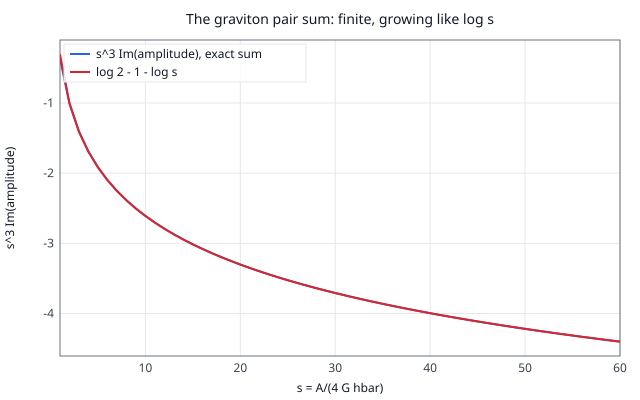

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [21]:
ss = 1:60;
exact = imag(eval(polylog(2, exp(-2*i./ss))./(2*ss.^2))).*ss.^3;
approx = eval(log(2) - 1 - log(ss));
p = plot(ss, exact);
p = show(p, plot(ss, approx));
p = legend(p, "s^3 Im(amplitude), exact sum", "log 2 - 1 - log s");
labels(title(p, "The graviton pair sum: finite, growing like log s"), "s = A/(4 G hbar)", "s^3 Im(amplitude)")

The two curves agree to within the width of the line, even for corners only a few Planck areas across: the exact
amplitude is finite and grows only like $\log s$. This is the pattern the paper proposes for gravity's ultraviolet problem: at fixed
$G$ the sum over intermediate states converges (its equation 4.30, from the Cauchy–Schwarz inequality), and the
divergences of perturbation theory come from expanding in $G$ before summing.

Keep the scope in view. This is one amplitude, in the framework the paper constructs. It shows that summing first and
expanding first can differ, and how a divergence can appear in the expansion of a finite quantity. It does not show that
all gravitational amplitudes, or all ultraviolet divergences of gravity, are finite; the general convergence claim rests
on the paper's equation 4.30 and on its construction of the state, which are for the reader to validate.

**Try this.** Evaluate the amplitude at $s = 1000$ and compare its imaginary part with $(\log 2 - 1 - \log s)/s^3$. How
does the relative error change from $s = 100$?

## 10. Why the area spectrum is discrete (advanced)

Restrict the clock to readings at most $\ell$. Section 5 showed that this bounds the area, $A \le 4\pi\ell^2/(1 -
\epsilon)^2$ (equation 5.21d), so the dimensionless area $s = A/4G\hbar$ lies in $[0, s_*]$:

In [22]:
simplify((4*pi*l^2/(1 - ep)^2)/(4*G*hbar))

pi*l^2/(G*hbar*(1-ep)^2)

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

That is $s_* = \pi\ell^2/G\hbar(1 - \epsilon)^2$ (equation 5.30a). Bounded is not yet finite: infinitely many states
could crowd into a narrow interval of areas. The paper's finiteness argument is subtler than the area bound, and it is
the heart of the paper, so this section goes slowly.

The idea in one paragraph. Gluing two halves of a diamond along a cut at the corner inserts a complete set of
intermediate states there, and the result must equal the amplitude computed without the cut. A boost at the corner
changes a graviton correlation by a definite amount. The paper argues that if the bounded range of areas held infinitely
many states, the cut amplitudes could not reproduce that change, and the two constructions would disagree. The
conclusion rests on precise amplitude identities and inequalities in the paper's section 5.2 and appendix D.2, not on
the bounded area alone, and not on a general theorem about infinite-dimensional Hilbert spaces.

**The chain of reasoning** (paper section 5.2):

1. **Geometric constraint.** A bounded clock bounds the area: $0 \le s \le s_*$ (equations 5.21 and 5.30a). Every state
   of the diamond enters the trace with a weight between $e^{-s_*}$ and 1 (5.30c).
2. **Quantum hypothesis, to be refuted.** Suppose the diamond's Hilbert space $\mathcal H_D$ is infinite-dimensional.
   Cut the allowed range $[0, s_*]$ into finitely many narrow intervals; one of them, $I$, must then contain infinitely
   many orthogonal states.
3. **What a boost does on the cut.** A boost of rapidity $\eta$ at the corner acts on a state of area $s$ by the phase
   $e^{i\eta s/2\pi}$. On states whose areas sit close to one value $s_0$ it is nearly one overall phase, and an overall
   phase changes no expectation value. Quantitatively (equation 5.32), for a bounded observable $O$ and the normalized
   state $\rho_P$ on a set of intermediate states,
   $$\left|\langle O\rangle_{\eta,P} - \langle O\rangle_{0,P}\right| \le \frac{|\eta|\,\|O\|}{\pi}\sqrt{\operatorname{Tr}\rho_P(\hat s - s_0)^2}.$$
4. **Observable test without the cut.** On the smooth geometry, put one graviton insertion just before the corner at
   affine distance $-d$ and one just after at $d$. Their correlation in the freely falling vacuum is $-c/(u - u')^2$
   (equation 5.28d). The boost moves the second insertion to $e^\eta d$ and rescales it by $e^\eta$, so the correlation
   changes by a definite, nonzero amount (equation 5.29, checked below). The paper turns it into a bounded observable
   $O = \sin(j_L\sigma_L)\sin(j_R\sigma_R)$ whose change $\delta_\eta$ is nonzero (5.33, 5.34).
5. **Arranging the states.** With infinitely many states in $I$, the paper groups the basis into cycles of length $r$,
   each with at most one state outside $I$ (its figure 29). For $I$ narrow and $r$ large, step 3 keeps the boost change on
   every finite union of cycles below $\delta_\eta/2$.
6. **Consistency requirement.** By diffeomorphism invariance, the amplitude with the cut, summed over all cycles, must
   reproduce the uncut amplitude (the paper's section 3.6 and equation 4.29).
7. **Contradiction.** For $X = \Delta_\eta O - \tfrac12\delta_\eta$ the uncut amplitude is strictly positive, while every
   partial sum on the cut is at most zero (equation 5.38). Partial sums that are all $\le 0$ cannot approach a positive
   number, so the hypothesis of step 2 fails: $\mathcal H_D$ is **finite-dimensional**, and the area takes finitely many
   values $A_1, \ldots, A_m$ (equation 5.40).

Step 4 is the one calculation you can redo exactly. The correlation changes by the factor (equation 5.29)

$$\frac{e^\eta\,G(-d, e^\eta d)}{G(-d, d)} = \frac{4e^\eta}{(1 + e^\eta)^2} = 1 - \tanh^2(\eta/2).$$

In [23]:
gr = e1*(-c/(-d - e1*d)^2)/(-c/(-d - d)^2);
simplify(gr - 4*e1/(1 + e1)^2)
simplify(4*exp(eta)/(1 + exp(eta))^2 - (1 - ((exp(eta) - 1)/(exp(eta) + 1))^2))

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

(Here `e1` stands for $e^\eta$, and $\tanh(\eta/2) = (e^\eta - 1)/(e^\eta + 1)$.) The boost changes something
measurable, by the fraction $\tanh^2(\eta/2)$:

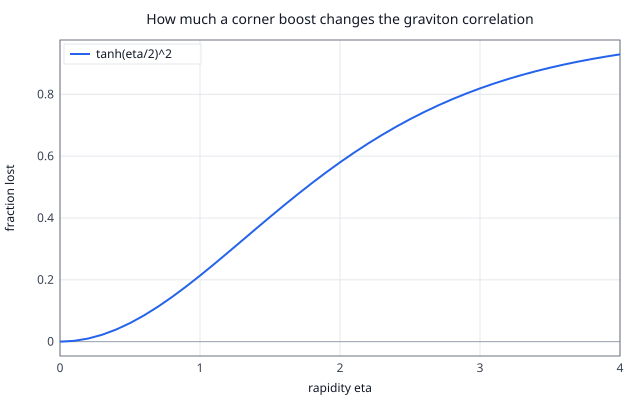

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [24]:
eta = 0:0.1:4;
p = plot(eta, ((exp(eta) - 1)./(exp(eta) + 1)).^2);
labels(title(legend(p, "tanh(eta/2)^2"), "How much a corner boost changes the graviton correlation"), "rapidity eta", "fraction lost")

Step 3 can be made concrete too. If the states on the cut have areas within a band of half-width $w$ around $s_0$, the
square root in 5.32 is at most $w$, so the change is at most $|\eta|\,w/\pi$ for $\|O\| \le 1$. To keep it below
$\delta_\eta/2$ the band must be narrower than $\pi\delta_\eta/(2|\eta|)$. For a boost of rapidity 1 and an observable
that the boost changes by $\delta_\eta = 0.1$:

In [25]:
eta1 = 1; de = 1/10;
wmax = pi*de/(2*eta1)
eval(wmax)

pi/20

0.15707963267948966

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A band of half-width about 0.16 in $s = A/4G\hbar$, a fraction of a Planck area, is narrow, but with infinitely many
states some band that narrow holds infinitely many of them, and that is all step 5 needs.

What the computations here do and do not show. They reproduce step 4 exactly and illustrate step 3. They do not verify
the bounds of appendix D.2 used in steps 4 and 5 (the remainder estimates 5.36 and D.36), the claim that the cut and
uncut amplitudes must agree in this construction, or the construction of the state on which all of it rests. Those are
the places where the argument has to be validated.

With finitely many states and the weight $e^{-s}$ of section 7, the diamond's state is the density matrix
$\rho_D = e^{-\hat s}/Z$, with $Z = \operatorname{Tr}e^{-\hat s}$ (equation 5.39).

**In your own words.** Explain the contradiction of step 7 without formulas: what does the boost do with the cut, what
does it do without, and why must the two agree?

**Try this.** For which rapidity $\eta$ does the boost remove half of the correlation?

## 11. The entropy and its logarithmic correction (advanced)

Four different things meet in this section, and they have different status:

1. **An identity.** For any density matrix $\rho = e^{-\hat s}/Z$, $S = \langle s\rangle + \log Z$. This is plain
   algebra and holds for every spectrum.
2. **An identification.** That the first term, $\langle A\rangle/4G\hbar$, is the Bekenstein–Hawking entropy. The paper
   makes it only when the corner is a marginally trapped surface (its local notion of a horizon, equation 5.51), with the
   boost weight of section 7.
3. **A calculation.** The coefficient of the logarithmic correction, $257/90$ (or $106/45$ at fixed mass), from a
   one-loop evaluation on a Schwarzschild background.
4. **Assumptions.** The coefficient depends on the ensemble (which areas and masses are summed), on the measure of
   equation 5.66, and on the clock bound. It is not a generic consequence of the area law; change the ensemble or the
   measure and it changes.

The code below reproduces 1 exactly and the arithmetic of 3. Items 2 and 4 are where validation is needed.

For a density matrix $\rho = e^{-\hat s}/Z$ the von Neumann entropy $S = -\operatorname{Tr}\rho\log\rho$ is
$\langle s\rangle + \log Z$ (equation 5.50), because $-\log\rho = \hat s + \log Z$. Check it on a toy spectrum with one
state of area 1, two of area 2 and three of area 3:

In [26]:
lev = [1 2 2 3 3 3];
Z = sum(exp(-lev))
pr = exp(-lev)/Z;
eval(entropy(pr))
eval(sum(lev.*pr) + log(Z))

1/e+2/exp(2)+3/exp(3)

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

1.4842914752679144

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.4842914752679146

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The first term, $\langle A\rangle/4G\hbar$, is the **Bekenstein–Hawking entropy**. When the corner is a marginally
trapped surface (a horizon), the paper argues that $\log Z$ grows only like the logarithm of the area, and computes the
coefficient. The steps, with the arithmetic you can redo:

1. **A topological integral.** At one loop the logarithmic term of the graviton determinant on the horizon comes from the
   integral of the curvature of the corner sphere, $\int_S R\,dA$ (equation 5.67). By the Gauss–Bonnet theorem it is
   $8\pi$ for any sphere, whatever its radius:

In [27]:
sph = metric([th ph], [r^2 0; 0 r^2*sin(th)^2]);
ricciscalar(sph)
integrate(integrate(ricciscalar(sph)*r^2*sin(th), th, 0, pi), ph, 0, 2*pi)

2/r^2

> `ricciscalar` (see `riccitensor`): Ricci tensor R_ab and Ricci scalar R.

8*pi

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

2. **The power of the area.** With it, the trace at area $s_b$ grows like $s_b^{106/45}$ (equation 5.67c), and the measure
   of equation 5.66 adds $\tfrac12$ to the power. The number $106/45$ is the one-loop coefficient of pure gravity, the
   same one that enters Sen's Euclidean calculation.
3. **From the power to the clock.** The paper relates $\log Z$ to the clock bound through a number $q$, the limiting
   ratio of the average clock reading to its maximum (equation 5.54), with $\log Z = \frac{q}{1 - q}\log\ell + \ldots$
   (5.58). Since $s_* \propto \ell^2$, a trace growing like $s^p$ means $q/(1 - q) = 2p$:

In [28]:
p = 106/45 + 1/2
q = 2*p/(1 + 2*p)
q/(2*(1 - q))

257/90

257/302

257/90

So $q = 257/302$ (equation 5.68), and the entropy of a large Schwarzschild black hole is (5.65)

$$S = \frac{\langle A\rangle}{4G\hbar} + \frac{257}{90}\log\frac{\langle A\rangle}{4G\hbar} + \ldots$$

4. **At fixed mass.** Areas $s_b \propto M^2$ of different masses are summed in the trace. Holding the mass fixed changes
   the measure by $ds_b/s_b^{1/2} \propto dM$, which removes $\tfrac12$ from the coefficient (5.69):

In [29]:
q/(2*(1 - q)) - 1/2

106/45

The coefficient $106/45$ is what the paper reports as agreeing with Sen's one-loop result for this ensemble (fixed mass,
angular momenta summed).

Two more identities from the paper's footnotes. Footnote 23 writes $q$ in terms of $x = (1 - \epsilon)r_h/\ell$ as
$q = 2x^2/(1 + x^2)$, and then the coefficient is $x^2/(1 - x^2)$; and the identity (5.60) it uses holds for every
reading $u$:

In [30]:
qx = 2*x^2/(1 + x^2);
simplify(qx/(2*(1 - qx)))
simplify(u^2/l + integrate((u/t)^2, t, u, l))

x^2/(1-x^2)

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

u

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

Footnote 24 adds how the states are spread over areas: the probability of an area below a fraction $a$ of the maximum
tends to $a^{q/2(1 - q)} = a^{257/90}$ (equation 5.63). Most of the weight sits near the top:

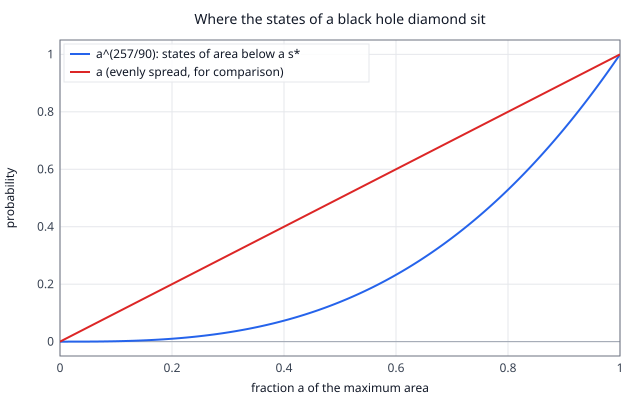

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [31]:
p = plot(a^(257/90), a, 0, 1);
p = show(p, plot(a, a, 0, 1));
p = legend(p, "a^(257/90): states of area below a s*", "a (evenly spread, for comparison)");
labels(title(p, "Where the states of a black hole diamond sit"), "fraction a of the maximum area", "probability")

**Try this.** If the one-loop coefficient were $106/45 + 1$ instead of $106/45$, what would $q$ and the entropy
coefficient be, in the area ensemble and at fixed mass?

**In your own words.** Which of the four items at the start of this section would change if a later paper found a
different one-loop coefficient, and which would not?

## 12. Two-sided black holes and entangled gravitons

The paper's section 5.4 asks whether the Hilbert space of a spacetime with two boundaries (like the two exteriors of an
eternal black hole) factorizes into left and right. It shows that the part of a connected state orthogonal to all
product states has zero norm (equation 5.73), so the connected geometry is a superposition of product states: an
entangled one. For one graviton mode of frequency $\omega$ the thermal state pairs $n$ gravitons on the left with $n$ on
the right (equation 5.75),

$$|\Psi_\omega\rangle \propto \sum_{n=0}^\infty e^{-nb\omega}\,|n\rangle_L|n\rangle_R, \qquad \langle a_L a_R\rangle = \frac{1}{2\sinh b\omega}.$$

With $x = e^{-b\omega}$, $a_La_R$ takes $|n\rangle|n\rangle$ to $n|n - 1\rangle|n - 1\rangle$, so
$\langle a_La_R\rangle = \sum_n n\,x^{2n-1}\big/\sum_n x^{2n}$:

In [32]:
pair = simplify(sum(n*x^(2*n-1), n, 1, inf)/sum(x^(2*n), n, 0, inf))
simplify(subs(pair, x, exp(-y)) - 1/(exp(y) - exp(-y)))

x/(1-x^2)

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

That is $x/(1 - x^2) = 1/(2\sinh b\omega)$. Summing such pairs over all frequencies $\nu$ gives the correlation of the
shear on the two horizons (equation 5.76), which uses

$$\int_0^\infty \frac{\nu\cos(\nu L)}{\sinh \pi\nu}\,d\nu = \frac{1}{4\cosh^2(L/2)}, \qquad L = \log\frac{u_L}{u_R},$$

so that the correlation is $-c/(u_L + u_R)^2$: the same as along a single horizon generator from $-u_L$ to $u_R$. Check
the integral at $L = 1$:

In [33]:
integrate(nu*cos(nu)/sinh(pi*nu), nu, 0, inf)
eval(1/(4*cosh(1/2)^2))

0.19661193324148188

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

0.19661193324148188

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** Show by hand that $u_Lu_R/(u_L + u_R)^2 = 1/(4\cosh^2(L/2))$ when $L = \log(u_L/u_R)$.

## 13. The classical limit

Finally, the paper's section 6 checks that the theory has the right classical limit. In a coherent state each
canonical variable fluctuates with variance of order $\hbar$, so averages follow the classical trajectory, and
invariance of the amplitude under field redefinitions gives Einstein's equations $R_{ab} - \tfrac12 Rg_{ab} +
\Lambda g_{ab} = 0$ (equation 6.4). At the next order the fluctuations themselves matter, because the field equations are
nonlinear: a fluctuation with zero average still shifts the average of a quadratic expression. The paper's equation 6.9a
says $\bar g = g + \tfrac12\Sigma^{IJ}\delta_I\delta_J g$. The same thing in one variable: average a nonlinear $f(q)$ over a
Gaussian of center $q^0$ and variance $v$:

In [34]:
integrate((q^3 - q)*exp(-(q - q0)^2/(2*v))/sqrt(2*pi*v), q, -inf, inf)
integrate(exp(c*q)*exp(-(q - q0)^2/(2*v))/sqrt(2*pi*v), q, -inf, inf)

q0*(q0^2+3*v-1)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

exp(c*(c*v/2+q0))

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

For the cubic the average is $f(q^0) + \tfrac12 v f''(q^0)$ exactly ($f'' = 6q$); for the exponential the shift is
$e^{c q^0}(e^{c^2v/2} - 1) \approx \tfrac12 v f''$ for small $v$. In gravity $v \sim \hbar$, and this shift is the
**backreaction** of graviton fluctuations on the average metric, the semiclassical Einstein equation (6.13).

How to read the paper's claims. The computations above are the checkable parts. The weight of the paper rests on three
arguments that are not computations: that the uncut and cut amplitudes must agree (the finiteness of section 10), that
the Gaussian state can be extended to all observables as claimed, and the one-loop evaluation of $q$. Those are what
experts will test, and what follow-up papers will confirm or correct.

**Try this.** Compute the average of $q^4$ over the Gaussian and compare with $f(q^0) + \tfrac12 vf''(q^0)$. Which term
is missing, and what order in $v$ is it?

## A map of the paper

| Step | The paper's claim | What this lesson computes | Level reached | What remains open |
|---|---|---|---|---|
| Area law (1) | $S = A/4G\hbar$ for black holes | the numbers for the Sun | reproduce | (established physics) |
| Null cones (2, 4) | constraints integrate along light rays, leaving free data | the focusing equation solved two ways | reproduce, understand | the full reduction (paper section 3, appendix A) |
| Clock (3) | a relational clock $u_*$ from the corner geometry | the AdS$_2$ clock and its flat limit | reproduce, understand | |
| Area bound (5) | bounded clock implies bounded area | Cauchy–Schwarz on a lopsided corner | reproduce, understand | |
| States and trace (6, 7) | orthonormal clock states; weight $e^{-A/4G\hbar}$ | orthogonality; $2\pi K/\hbar = A/4G\hbar$ | reproduce | |
| Gravitons (8, 9) | Fock space on a Gaussian state; finite sums at fixed $G$ | Gaussian moments; the dilogarithm vs the harmonic series | reproduce, understand | extension of the state to all observables; equation 4.30 in general |
| Finiteness (10) | a bounded diamond has finitely many states | the boost factor $\tanh^2(\eta/2)$; the band width in 5.32 | understand | the bounds of appendix D.2; that cut and uncut amplitudes agree |
| Entropy (11) | $S = \langle A\rangle/4G\hbar + \tfrac{257}{90}\log s$ | the identity; Gauss–Bonnet; the arithmetic of $q$ | reproduce | the identification with a horizon; the one-loop value of $q$; the ensemble |
| Two sides (12) | a connected geometry is an entangled superposition | thermal pair sums; the shear correlation integral | reproduce | equation 5.73 |
| Classical limit (13) | Einstein's equations and backreaction | Gaussian averages of $f(q)$ | reproduce, understand | |

In one paragraph: the paper cuts spacetime into causal diamonds, uses the null structure of their boundaries to reduce
gravity to free data with a relational clock, quantizes that data, and finds the Bekenstein–Hawking weight $e^{-A/4G\hbar}$
in the gluing of diamonds. Focusing bounds the area of a diamond with a bounded clock; a consistency argument between cut
and uncut amplitudes then makes its Hilbert space finite, and the count of states gives the area law with a logarithmic
correction. The first half of that story is calculation you can redo; the finiteness argument and the one-loop
coefficient are where the paper asks to be checked.

## Exercises

1. **A small black hole.** Compute $r_s$, $S$ and $T$ for a black hole of the mass of the Earth ($5.97 \times 10^{24}$
   kg). Would it be hotter or colder than the cosmic microwave background (2.7 K)?
2. **Flat limit of the clock.** Show with `limit` that the clock reading $u_*(w)$ of section 3 tends to
   $(1 - \epsilon)w/2$ as $L \to \infty$.
3. **Focusing in flat space.** Solve $\varrho'' = 0$ with $\varrho(0) = 1$ and $\varrho'(0) = -1/2$. When do the rays
   meet? Compare with section 5.
4. **Cauchy–Schwarz.** For $\varrho_S = 1 + a\cos\theta$, compute the ratio of section 5 as a function of $a$ and show
   it is at least 1 for $|a| < 1$.
5. **States.** Show that $\langle\Psi_m|\Psi_n\rangle = \delta_{mn}$ for any normalized $h$ on $[0, \ell]$, using the
   substitution $s = F(u_*)$.
6. **A second Gaussian moment.** For the Gaussian of section 8, show that $\langle a^\dagger a\rangle = 0$ and
   $\langle a a^\dagger\rangle = 1$ by computing $a\psi$ and $a^\dagger\psi$ with `diff`.
7. **Dilogarithm values.** Check that `polylog(2, 1)` is $\pi^2/6$ and that `eval(polylog(2, -1))` is $-\pi^2/12$. What
   does the sum of section 9 give at $s \to \infty$ with $s^2$ times the amplitude held fixed?
8. **Entropy bounds.** For $n$ states of equal area, show with `entropy` that the von Neumann entropy (natural logarithm,
   $k_B = 1$) is $S = \log n$. Which spectrum of 6 states maximizes $S$?

## Hints and answers

* **Section 1, Try this.** $S \propto M^2$, so doubling the mass quadruples the entropy. $T \propto 1/M$: adding energy
  cools the hole, a negative heat capacity.
* **Section 2, Try this.** Events in the past cone of $q$ but outside the future cone of $p$; they are outside the
  diamond.
* **Section 3, Try this.** The $w^3$ term $(1 - 3\epsilon^2 + 2\epsilon^3)w^3/48$ reaches 10% of
  $(1 - \epsilon)w/2$ near $w \approx 1.5$ when $\epsilon = 0.3$; the $w^5$ term is still small there.
* **Section 4, Try this.** $\Delta\Phi(1)$ becomes a quarter as large: $-\pi^2/16$ instead of $-\pi^2/4$.
* **Section 5, Try this.** Larger: $\sqrt{4/3} \approx 1.15$, because the corner is more lopsided.
* **Section 5, In your own words.** The shear term in the focusing equation is a square, so it can only bend the light
  rays together; the clock integrates $e^{\Xi} \ge 1$ and so reads at least its shear-free value. A clock that may not
  read past $\ell$ therefore cannot have a large corner.
* **Section 6, Try this.** $\int_0^1 3u^2\,du = 1$; $F = u^3$; the charge is $2\pi\int_0^1 9u^5\,du = 3\pi$.
* **Section 7, Try this.** $\log S \approx 177$, against $S \approx 10^{77}$: the correction is tiny for large black
  holes, which is why it tests a theory's details.
* **Section 7, In your own words.** In two dimensions infinitely many states (the $\Psi_n$) all enter with the same
  weight. In four dimensions the trace is finite only if the diamond has finitely many states, which section 10 argues.
* **Section 8, Try this.** `integrate((q - q0)^4*psi^2, q, -inf, inf)` gives $3\,dq^4$.
* **Section 9, Try this.** At $s = 1000$ the imaginary part is about $-7.21 \times 10^{-9}$; the approximation is off by a
  relative error of order $1/s^2$, a hundred times smaller than at $s = 100$.
* **Section 10, Try this.** $\tanh^2(\eta/2) = \tfrac12$ at $\eta = 2\operatorname{atanh}(1/\sqrt2) \approx 1.76$.
* **Section 10, In your own words.** With the cut, a boost on states of nearly equal area is nearly a phase and changes
  almost nothing; without the cut, the same boost moves a graviton and changes a correlation by a definite amount.
  Summing over a complete set of states at the cut is the identity, so both must give the same answer; with infinitely
  many states they cannot.
* **Section 11, Try this.** In the area ensemble the power is $p = 106/45 + 1 + 1/2 = 347/90$, so $q = 347/392$ and the
  coefficient is $347/90$; at fixed mass $\tfrac12$ comes off, giving $302/90 = 151/45$. Both coefficients move with the
  one-loop number, which is why it matters.
* **Section 11, In your own words.** Only item 3 (and the numbers in the arithmetic) would change; the identity is
  algebra and the identification with a horizon does not depend on the coefficient.
* **Section 12, Try this.** $(u_L + u_R)^2/(u_Lu_R) = u_L/u_R + 2 + u_R/u_L = e^L + 2 + e^{-L} = 4\cosh^2(L/2)$.
* **Section 13, Try this.** The average of $q^4$ is $q_0^4 + 6q_0^2v + 3v^2$; $\tfrac12 v f''$ gives the $6q_0^2v$, and
  the missing $3v^2$ is second order in $v$, so of order $\hbar^2$, beyond one loop.
* **Exercise 1.** $r_s \approx 8.9$ mm, $S \approx 9.4 \times 10^{65}$, $T \approx 0.021$ K: colder than the
  background, so it would absorb more than it emits.
* **Exercise 2.** `limit(subs(ustar, lc, ep*w/2), L, inf)` gives $(1 - \epsilon)w/2$.
* **Exercise 3.** $\varrho = 1 - u/2$ meets zero at $u = 2$: without focusing, converging rays still meet, but later.
* **Exercise 4.** $\int\varrho_S\,d\Omega = 4\pi$ and $A = \int\varrho_S^2\,d\Omega = 4\pi(1 + a^2/3)$, so the ratio
  $\sqrt{4\pi A}\big/\int\varrho_S\,d\Omega$ is $R(a) = \sqrt{1 + a^2/3}$, at least 1, and equal to 1 only for $a = 0$.
* **Exercise 5.** $ds = |h|^2 du$ maps $[0, \ell]$ onto $[0, 1]$ because $F(\ell) = 1$.
* **Exercise 6.** $a\psi = 0$, so $\langle a^\dagger a\rangle = \|a\psi\|^2 = 0$. With $a^\dagger = (q - q^0)/(2\Delta q) -
  \Delta q\,d/dq$, $a^\dagger\psi = (q - q^0)\psi/\Delta q$, whose squared norm is 1.
* **Exercise 7.** $s^2$ times the amplitude is $\operatorname{Li}_2(e^{-2i/s})/2 \to \pi^2/12$.
* **Exercise 8.** `entropy([1/6 1/6 1/6 1/6 1/6 1/6])` is $\log 6$; equal areas (equal probabilities) maximize it.

## Sources

1. V. Chandrasekaran, "An algebraic quantization of gravity from the null cone", arXiv:2611.34924 (2026), version 1.
2. J. D. Bekenstein, "Black holes and entropy", *Physical Review D* 7 (1973) 2333–2346.
3. S. W. Hawking, "Particle creation by black holes", *Communications in Mathematical Physics* 43 (1975) 199–220.
4. R. Jackiw, "Lower dimensional gravity", *Nuclear Physics B* 252 (1985) 343–356; C. Teitelboim, "Gravitation and
   Hamiltonian structure in two spacetime dimensions", *Physics Letters B* 126 (1983) 41–45.
5. A. Sen, "Logarithmic corrections to Schwarzschild and other non-extremal black hole entropy in different
   dimensions", *Journal of High Energy Physics* 2013(04) 156.
6. A. K. Raychaudhuri, "Relativistic cosmology I", *Physical Review* 98 (1955) 1123–1126.
7. R. Haag, *Local Quantum Physics*, 2nd ed., Springer (1996), chapter III (the GNS construction of section 8).
8. R. M. Wald, *Quantum Field Theory in Curved Spacetime and Black Hole Thermodynamics*, University of Chicago Press
   (1994), chapter 5 (thermal pairs of section 12).
9. L. Lewin, *Polylogarithms and Associated Functions*, North-Holland (1981), chapter 1 (the dilogarithm of section 9).